#### 🧱 Diagnóstico de Marca Empleadora — KFC vs. Peers
#### Sentiment Analysis (Transformers) + Topic Modeling (BERTopic)

#### Glassdoor Reviews · Caso Práctico NLP · Evolve Academy

Identificar las fortalezas y áreas de mejora de **KFC** como empleador a partir de las opiniones de sus trabajadores en Glassdoor, comparándolas con sus competidores directos para fundamentar un plan de atracción y retención de talento.

- Peers elegidos: **McDonald's, Domino's, Starbucks y Subway.** 
  * Cadenas líderes del sector *Quick Service Restaurants* (QSR) que compiten directamente con KFC por:
      * **Perfiles profesionales:** Cajeros, cocineros, *shift leaders*, *store managers* y repartidores.
      * **Dinámicas laborales homogéneas:** Estructuras de salarios de entrada, turnos rotativos, alta intensidad de servicio, retos de conciliación familiar y expectativas de promoción interna.


| Sección | Contenido |
|:---:|---|
| 0 | Carga y preparación de datos |
| 1 | EDA |
| 2 | Sentiment Analysis con DistilBERT  |
| 3 | Topic Modeling con BERTopic|
| 4 | Comparación con Peers|
| 5 | Análisis por Empleado Actuales vs. Antiguos |
| 6 | Matriz de Priorización de RRHH |
| 7 | Conclusiones, recomendaciones para RRHH y limitaciones del análisis |

In [1]:
import pyarrow
print(pyarrow.__version__)

25.0.1


## 0. Carga y preparación de datos

* Target: KFC
* Peers: McDonald's, Domino's, Starbucks y Subway

In [2]:
# Carga y Preparación de Datos

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

TARGET = "KFC"
PEERS = ["McDonald-s", "Domino's", "Starbucks", "Subway"]
FIRMS = [TARGET] + PEERS
MAX_POR_EMPRESA =2000 # Límite máximo de reseñas por empresa.
SEED = 42

parquet_path = 'glassdoor_reviews_hr.parquet'
csv_path = 'glassdoor_reviews_empresas_KFC.csv'

def generar_csv_empresas(parquet_path, csv_path, max_por_empresa, seed):
    raw = pd.read_parquet(parquet_path, filters=[('firm', 'in', FIRMS)])
    raw['date'] = pd.to_datetime(raw['date_review'], errors='coerce')
    raw = raw.dropna(subset=['date']).copy()
    raw['year'] = raw['date'].dt.year.astype(int)

    muestras = []
    for firma in FIRMS:
        datos_empresa = raw[raw["firm"] == firma].copy()
        if len(datos_empresa) == 0:
            continue

        anios = sorted(datos_empresa["year"].unique())
        max_por_anio = max_por_empresa // len(anios)

        for anio, grupo in datos_empresa.groupby("year"):
            n = min(max_por_anio, len(grupo))
            muestras.append(grupo.sample(n=n, random_state=seed))

    df = pd.concat(muestras, ignore_index=True)
    df = df.sort_values(['firm', 'year', 'date'], ascending=[True, True, False]).reset_index(drop=True)
    df.to_csv(csv_path, index=False)
    return df

df = generar_csv_empresas(parquet_path, csv_path, MAX_POR_EMPRESA, SEED)
df = pd.read_csv(csv_path)
df.head()

,firm,date_review,current,overall_rating,recommend,pros,cons,date,year
0,Domino's,2018-12-30,"Current Employee, less than 1 year",2.0,x,Coworkers are great people and nice\nThe manag...,Pay is iffy\nTerrible hours\nConditions in sto...,2018-12-30,2018
1,Domino's,2018-12-29,"Current Employee, less than 1 year",3.0,v,"All good, its amazing , work culture everything","Public interaction sometimes feel irritated, r...",2018-12-29,2018
2,Domino's,2018-12-29,"Current Employee, more than 3 years",4.0,v,Flexible hours \r\nRewarding work\r\nPostive t...,Long hours and not much employee appreciation,2018-12-29,2018
3,Domino's,2018-12-28,"Former Employee, more than 1 year",5.0,o,"Easy, quick money, great atmosphere, friendly ...","low pay, little hours, difficult to receive mo...",2018-12-28,2018
4,Domino's,2018-12-28,"Current Employee, less than 1 year",3.0,x,"Tips, and driving your own car","Late night shifts, sometimes gas compensation ...",2018-12-28,2018


---
### Limpieza y Variables Derivadas

 Crear variables: 
- 'tipo_empleado'("Current Employe = Actual", "Former Employe = Antiguo", "Otros = Desconocido") 
- 'anios_antiguedad'(# años) basado en la columna "current"
- 'recomienda'('v=Sí', 'o=Neutral', 'x=No') basado en la columna 'recommend'.

 Limpieza de texto pros y cons

In [3]:
def situacion(s):
    s = str(s).lower()
    if s.startswith('current'): return 'Actual'
    if s.startswith('former'): return 'Antiguo'
    return 'Desconocido'

def antiguedad(s):
    m = re.search(r'(less|more) than (\d+) year', str(s))
    return f'{m.group(1)} than {m.group(2)}y' if m else 'n/d'

df['tipo_empleado'] = df['current'].map(situacion)
df['anios_antiguedad'] = df['current'].map(antiguedad)
df['recomienda'] = df['recommend'].map({'v': 'Si', 'o': 'Neutral', 'x': 'No'})

for col in ['pros', 'cons']:
    df[col] = df[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()


display('Dataset', df.head())
display("Valores null", df.isnull().sum())

def tipo_variables(df):
    dtypes = df.dtypes
    categorical_cols = []
    numerical_cols = []
    for col, dtype in dtypes.items():
        if pd.api.types.is_numeric_dtype(dtype):
            numerical_cols.append(col)
        else:
            categorical_cols.append(col)
    return numerical_cols, categorical_cols

vbles = tipo_variables(df)
num_vbles =vbles[0]
cat_vbles = vbles[1]

display("Variables Categoricas", cat_vbles)
display("Variables Numericas", num_vbles)

'Dataset'

,firm,date_review,current,overall_rating,recommend,pros,cons,date,year,tipo_empleado,anios_antiguedad,recomienda
0,Domino's,2018-12-30,"Current Employee, less than 1 year",2.0,x,Coworkers are great people and nice The manage...,Pay is iffy Terrible hours Conditions in store...,2018-12-30,2018,Actual,less than 1y,No
1,Domino's,2018-12-29,"Current Employee, less than 1 year",3.0,v,"All good, its amazing , work culture everything","Public interaction sometimes feel irritated, r...",2018-12-29,2018,Actual,less than 1y,Si
2,Domino's,2018-12-29,"Current Employee, more than 3 years",4.0,v,Flexible hours Rewarding work Postive teamwork...,Long hours and not much employee appreciation,2018-12-29,2018,Actual,more than 3y,Si
3,Domino's,2018-12-28,"Former Employee, more than 1 year",5.0,o,"Easy, quick money, great atmosphere, friendly ...","low pay, little hours, difficult to receive mo...",2018-12-28,2018,Antiguo,more than 1y,Neutral
4,Domino's,2018-12-28,"Current Employee, less than 1 year",3.0,x,"Tips, and driving your own car","Late night shifts, sometimes gas compensation ...",2018-12-28,2018,Actual,less than 1y,No


'Valores null'

firm                0
date_review         0
current             0
overall_rating      0
recommend           0
pros                0
cons                0
date                0
year                0
tipo_empleado       0
anios_antiguedad    0
recomienda          0
dtype: int64

'Variables Categoricas'

['firm',
 'date_review',
 'current',
 'recommend',
 'pros',
 'cons',
 'date',
 'tipo_empleado',
 'anios_antiguedad',
 'recomienda']

'Variables Numericas'

['overall_rating', 'year']

In [4]:

import re

def clean_review_text(text, keep_emojis=True, lowercase=True, truncate_length=256):
    text = str(text)

    # 1. Whitespace
    text = text.replace('\r\n', ' ')
    text = text.replace('\r', ' ')
    text = text.replace('\t', ' ')

    # 2. Corregir errores de codificación conocidos
    text = text.replace('â€¢', ' ')   # • mal codificado
    text = text.replace('â€™', "'")
    text = text.replace('â€œ', '"')
    text = text.replace('â€\x9d', '"')

    # 3. URLs y emails
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'\S+@\S+\.\S+', ' ', text)

    # 4. HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # 5. Corregir viñetas/separadores al inicio
    text = text.replace('â€¢', ' ')
    text = re.sub(r'^[\s=•-]+', '', text)

    # 6. Normalizar comillas y puntuación Unicode
    text = text.replace('\u2019', "'")
    text = text.replace('\u2018', "'")
    text = text.replace('\u201c', '"')
    text = text.replace('\u201d', '"')
    text = text.replace('\u2026', '...')
    text = text.replace('\u2014', '-')
    text = text.replace('\u2022', ' ')
    text = text.replace('\ufe0f', '')

    # 7. Caracteres sin valor semántico
    text = re.sub(r'[=*~;]', ' ', text)

    # 8. Emojis
    if not keep_emojis:
        text = re.sub(r'[^\x00-\x7F]+', ' ', text)

    # 10. Lowercase
    if lowercase:
        text = text.lower()
    return text

# Aplicar limpieza sobre pros y cons
df['pros_clean'] = df['pros'].apply(clean_review_text)
df['cons_clean'] = df['cons'].apply(clean_review_text)

# Verificar que no hay Null
print("Valores null en pros_clean:", df['pros_clean'].isnull().sum())
print("Valores null en cons_clean:", df['cons_clean'].isnull().sum())

df.to_csv("limpieza_datos.csv", index=False) 

Valores null en pros_clean: 0
Valores null en cons_clean: 0


---
## 1. EDA

* Métricas por empresa
* Rating actuales vs antiguos
* Evolución temporal del rating

In [5]:
# --- 1. Métricas por empresa ---
def calcular_metricas(df):
    resumen = df.groupby("firm").agg(
        n_reviews=("overall_rating", "count"),
        rating_medio=("overall_rating", "mean"),
        pct_recomienda=("recomienda", lambda x: np.mean(x == "Si") * 100),
        total_trabajadores=("tipo_empleado", lambda x: np.sum(x == "Actual"))
    ).reset_index()

    return resumen

metricas = calcular_metricas(df)
metricas

,firm,n_reviews,rating_medio,pct_recomienda,total_trabajadores
0,Domino's,1998,3.386386,37.937938,806
1,KFC,1902,3.317035,32.176656,803
2,McDonald-s,1998,3.393894,29.629630,780
3,Starbucks,1998,3.758759,41.941942,912
4,Subway,1998,3.315816,31.681682,688


'empleados actuales vs antiguos'

,firm,tipo_empleado,rating_medio,n_reviews
0,Domino's,Actual,3.553350,806
1,Domino's,Antiguo,3.273490,1192
2,KFC,Actual,3.508095,803
3,KFC,Antiguo,3.177434,1099
4,McDonald-s,Actual,3.541026,780
5,McDonald-s,Antiguo,3.299672,1218
6,Starbucks,Actual,3.906798,912
7,Starbucks,Antiguo,3.634438,1086
8,Subway,Actual,3.500000,688
9,Subway,Antiguo,3.219084,1310


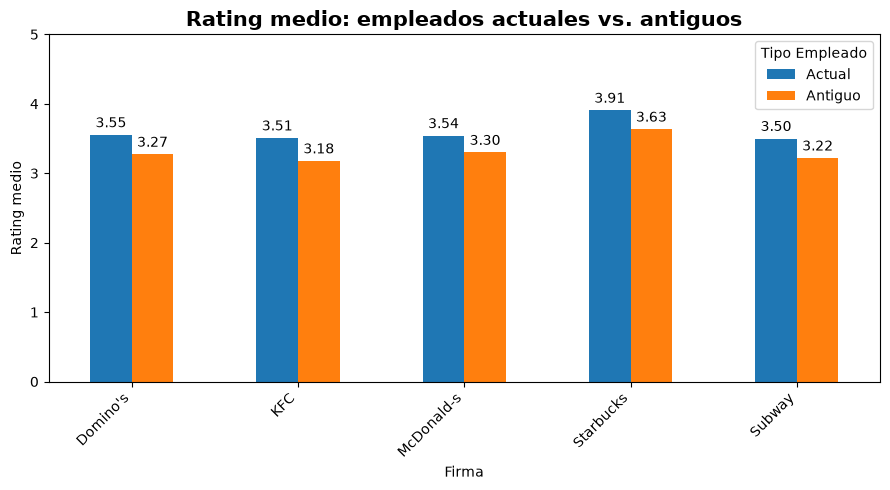

In [6]:
# --- 2. Comparación de rating: empleados actuales vs antiguos ---
rating_actual_vs_antiguo = df.groupby(["firm", "tipo_empleado"]).agg(
    rating_medio=("overall_rating", "mean"),
    n_reviews=("overall_rating", "count")
).reset_index()

display("empleados actuales vs antiguos", rating_actual_vs_antiguo)

# Convertir "situacion" en columnas
grafico = rating_actual_vs_antiguo.pivot(
    index="firm",
    columns="tipo_empleado",
    values="rating_medio"
)

# Gráfico
ax = grafico.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Rating medio: empleados actuales vs. antiguos",
          fontsize=15, fontweight="bold")
plt.xlabel("Firma")
plt.ylabel("Rating medio")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 5)

# Mostrar valores encima de las barras
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.legend(title="Tipo Empleado")
plt.tight_layout()
plt.show()

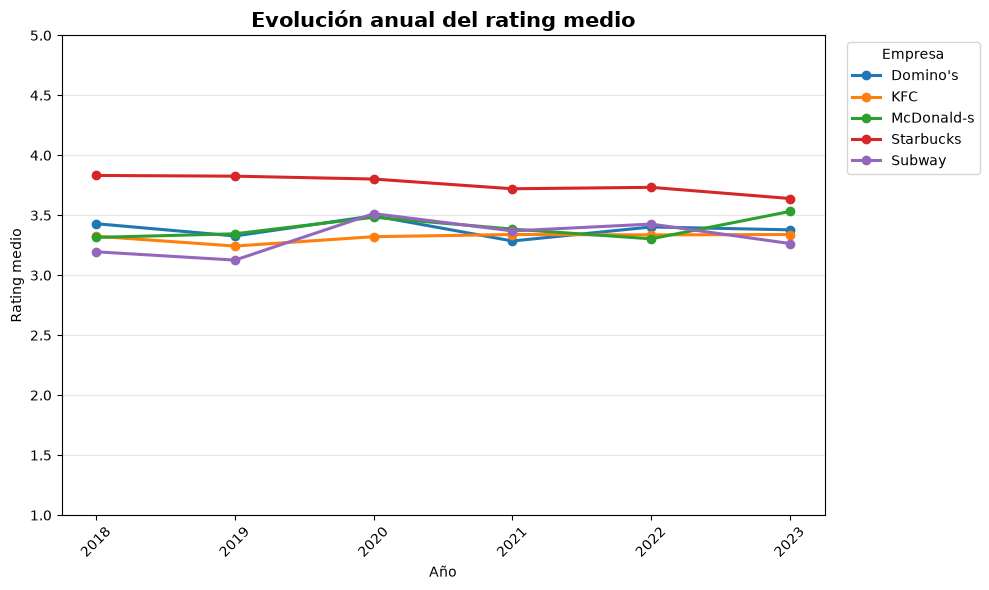

In [7]:
# --- 3. Evolución temporal del rating (mensual)---
rating_anual = df.groupby(["firm", "year"]).agg(
    rating_medio=("overall_rating", "mean"),
    n_reviews=("overall_rating", "count")
).reset_index()


plt.figure(figsize=(10, 6))
empresas = rating_anual["firm"].unique()
anios_ordenados = sorted(rating_anual["year"].unique())
for firma in empresas:
    datos = rating_anual[rating_anual["firm"] == firma].sort_values("year")
    plt.plot(
        datos["year"],
        datos["rating_medio"],
        marker="o",
        markersize=6,
        linewidth=2.2,
        label=firma
    )

plt.title("Evolución anual del rating medio", fontsize=15, fontweight="bold")
plt.xlabel("Año")
plt.ylabel("Rating medio")
plt.ylim(1, 5)
plt.xticks(anios_ordenados, rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Empresa", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Interpretación EDA
- Empleados actuales → presenta los ratings medios más altos.
- Rating temporal
    Starbucks-> el mejor rating,
    KFC -> un rating relativamente estable.

---
## 2. Sentiment Analysis con DistilBERT

- Control de calidad para verificar que el sentimiento predominante en pros es el positivo y en cons es en negativo.
- Utilizar  `distilbert-base-uncased-finetuned-sst-2-english` (POSITIVE / NEGATIVE, sin clase neutral) con `truncation=True`.


In [8]:
# ANALISIS SENTIMIENTO EN PROS Y CONS (DistilBERT)
import torch
from transformers import pipeline, AutoTokenizer

model_name = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(model_name)

sentiment_analyzer = pipeline(
    "sentiment-analysis",
    model=model_name,
    tokenizer=tokenizer,
    truncation=True,
    max_length=512,
    batch_size=32
)

# Analaisis de PROS
print("Procesando sentimiento en PROS...")
res_pros = sentiment_analyzer(df['pros_clean'].tolist())
df['sent_pro_label'] = [r['label'] for r in res_pros]
df['sent_pro_score'] = [r['score'] for r in res_pros]

# Analaisis de CONS
print("Procesando sentimiento en CONS...")
res_cons = sentiment_analyzer(df['cons_clean'].tolist())
df['sent_con_label'] = [r['label'] for r in res_cons]
df['sent_con_score'] = [r['score'] for r in res_cons]


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Procesando sentimiento en PROS...
Procesando sentimiento en CONS...


In [9]:
display(df.head(5))
df_sent = df[
    [
        'firm',
        'tipo_empleado',
        'overall_rating',
        'year',
        'pros_clean',
        'sent_pro_label',
        'cons_clean',
        'sent_con_label',
    ]
]

df_sent.to_csv(
    "analisis_sentimiento.csv",
    index=False
)# salvar el analisis de sentimiento en un archivo CSV para su posterior análisis

,firm,date_review,current,overall_rating,recommend,pros,cons,date,year,tipo_empleado,anios_antiguedad,recomienda,pros_clean,cons_clean,sent_pro_label,sent_pro_score,sent_con_label,sent_con_score
0,Domino's,2018-12-30,"Current Employee, less than 1 year",2.0,x,Coworkers are great people and nice The manage...,Pay is iffy Terrible hours Conditions in store...,2018-12-30,2018,Actual,less than 1y,No,coworkers are great people and nice the manage...,pay is iffy terrible hours conditions in store...,POSITIVE,0.999824,NEGATIVE,0.999506
1,Domino's,2018-12-29,"Current Employee, less than 1 year",3.0,v,"All good, its amazing , work culture everything","Public interaction sometimes feel irritated, r...",2018-12-29,2018,Actual,less than 1y,Si,"all good, its amazing , work culture everything","public interaction sometimes feel irritated, r...",POSITIVE,0.999889,POSITIVE,0.995181
2,Domino's,2018-12-29,"Current Employee, more than 3 years",4.0,v,Flexible hours Rewarding work Postive teamwork...,Long hours and not much employee appreciation,2018-12-29,2018,Actual,more than 3y,Si,flexible hours rewarding work postive teamwork...,long hours and not much employee appreciation,POSITIVE,0.999836,NEGATIVE,0.999667
3,Domino's,2018-12-28,"Former Employee, more than 1 year",5.0,o,"Easy, quick money, great atmosphere, friendly ...","low pay, little hours, difficult to receive mo...",2018-12-28,2018,Antiguo,more than 1y,Neutral,"easy, quick money, great atmosphere, friendly ...","low pay, little hours, difficult to receive mo...",POSITIVE,0.999747,NEGATIVE,0.999294
4,Domino's,2018-12-28,"Current Employee, less than 1 year",3.0,x,"Tips, and driving your own car","Late night shifts, sometimes gas compensation ...",2018-12-28,2018,Actual,less than 1y,No,"tips, and driving your own car","late night shifts, sometimes gas compensation ...",POSITIVE,0.986738,NEGATIVE,0.997777


In [10]:
# ------------------------------------------------------------------------------
# Métrica de Control de Calidad por Empresa (%)
# ------------------------------------------------------------------------------
control_calidad = df.groupby('firm').agg(
    n_reviews=('firm', 'count'),
    pct_pros_positivos=('sent_pro_label', lambda x: (x == 'POSITIVE').mean() * 100),
    pct_cons_negativos=('sent_con_label', lambda x: (x == 'NEGATIVE').mean() * 100)
).round(2).reset_index()
display("=== TABLA DE CONTROL DE CALIDAD DEL SENTIMIENTO POR EMPRESA (%) ===", control_calidad)


global_pros_pos = (df['sent_pro_label'] == 'POSITIVE').mean() * 100
global_cons_neg = (df['sent_con_label'] == 'NEGATIVE').mean() * 100

print(f"\n[MÉTRICA GLOBAL] Pros clasificados como POSITIVE: {global_pros_pos:.2f}%")
print(f"[MÉTRICA GLOBAL] Cons clasificados como NEGATIVE: {global_cons_neg:.2f}%")

'=== TABLA DE CONTROL DE CALIDAD DEL SENTIMIENTO POR EMPRESA (%) ==='

,firm,n_reviews,pct_pros_positivos,pct_cons_negativos
0,Domino's,1998,84.83,86.84
1,KFC,1902,87.91,84.07
2,McDonald-s,1998,88.59,84.48
3,Starbucks,1998,93.09,82.78
4,Subway,1998,84.48,85.79



[MÉTRICA GLOBAL] Pros clasificados como POSITIVE: 87.78%
[MÉTRICA GLOBAL] Cons clasificados como NEGATIVE: 84.80%


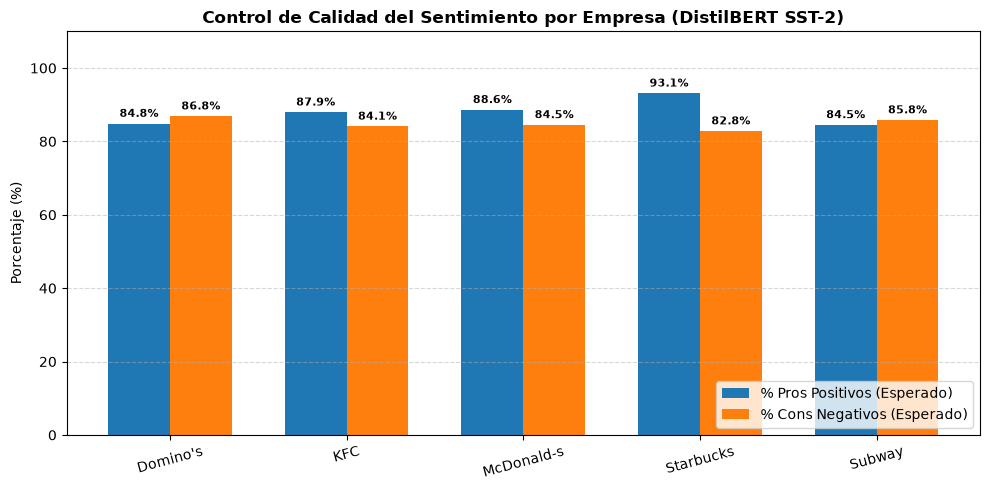

In [11]:
# ------------------------------------------------------------------------------
# Gráfico Comparativo por Empresa
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(control_calidad['firm']))
width = 0.35

rects1 = ax.bar(x - width/2, control_calidad['pct_pros_positivos'], width, label='% Pros Positivos (Esperado)')
rects2 = ax.bar(x + width/2, control_calidad['pct_cons_negativos'], width, label='% Cons Negativos (Esperado)')

ax.set_ylabel('Porcentaje (%)')
ax.set_title('Control de Calidad del Sentimiento por Empresa (DistilBERT SST-2)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(control_calidad['firm'], rotation=15)
ax.set_ylim(0, 110)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Añadir valores numéricos sobre cada barra
for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

In [12]:
# MUESTRA DE CASOS DISCORDANTES (TARGET VS. PEERS)
lista_empresas = df['firm'].unique()

for empresa in lista_empresas:
    print(f"{'='*20} {empresa.upper()}{'='*20}")

    # 1. CONS EVALUADOS COMO POSITIVE (CONTRADICCIÓN EN CONTRAS)
    cons_disc = df[(df['firm'] == empresa) & (df['sent_con_label'] == 'POSITIVE')]
    print(f"\nCONS DISCORDANTES (Evaluados como POSITIVE): {len(cons_disc)} casos en total")
    if len(cons_disc) > 0:
        display(cons_disc[['overall_rating', 'cons', 'sent_con_label', 'sent_con_score']].head(3))
    else:
        print("   → No se encontraron cons discordantes para esta empresa.")

    # 2. PROS EVALUADOS COMO NEGATIVE (CONTRADICCIÓN EN PROS)
    pros_disc = df[(df['firm'] == empresa) & (df['sent_pro_label'] == 'NEGATIVE')]
    print(f"\nPROS DISCORDANTES (Evaluados como NEGATIVE): {len(pros_disc)} casos en total")
    if len(pros_disc) > 0:
        display(pros_disc[['overall_rating', 'pros', 'sent_pro_label', 'sent_pro_score']].head(3))
    else:
        print("   → No se encontraron pros discordantes para esta empresa.")

==================== DOMINO'S====================

CONS DISCORDANTES (Evaluados como POSITIVE): 263 casos en total


,overall_rating,cons,sent_con_label,sent_con_score
1,3.0,"Public interaction sometimes feel irritated, r...",POSITIVE,0.995181
14,5.0,Very high pressure working and lots of work to...,POSITIVE,0.999738
18,4.0,Somewhat disorganized but improving daily.,POSITIVE,0.989646



PROS DISCORDANTES (Evaluados como NEGATIVE): 303 casos en total


,overall_rating,pros,sent_pro_label,sent_pro_score
6,3.0,Became very close like family Very busy,NEGATIVE,0.911048
11,2.0,It consists of mindless work for the most part.,NEGATIVE,0.999290
21,2.0,There really aren't any Pros to working part-t...,NEGATIVE,0.998143


==================== KFC====================

CONS DISCORDANTES (Evaluados como POSITIVE): 303 casos en total


...

,overall_rating,pros,sent_pro_label,sent_pro_score
5906,5.0,Free pound of coffee every week Employee 401k ...,NEGATIVE,0.978983
5913,3.0,"Make your own schedule, control hiring,",NEGATIVE,0.945613
5923,5.0,"Get a discount when off, get free beverages wh...",NEGATIVE,0.741561


==================== SUBWAY====================

CONS DISCORDANTES (Evaluados como POSITIVE): 284 casos en total


,overall_rating,cons,sent_con_label,sent_con_score
7897,3.0,You have to learn everything from the start.,POSITIVE,0.990661
7911,3.0,Working by yourself a lot of the time.,POSITIVE,0.645163
7926,4.0,No cons for this position,POSITIVE,0.996402



PROS DISCORDANTES (Evaluados como NEGATIVE): 310 casos en total


,overall_rating,pros,sent_pro_label,sent_pro_score
7900,3.0,You got free food. Easy job. Not much to it.,NEGATIVE,0.998949
7918,3.0,"Flexible scheduling, No room for improvement.",NEGATIVE,0.993481
7920,4.0,Get subway for your meal,NEGATIVE,0.950573


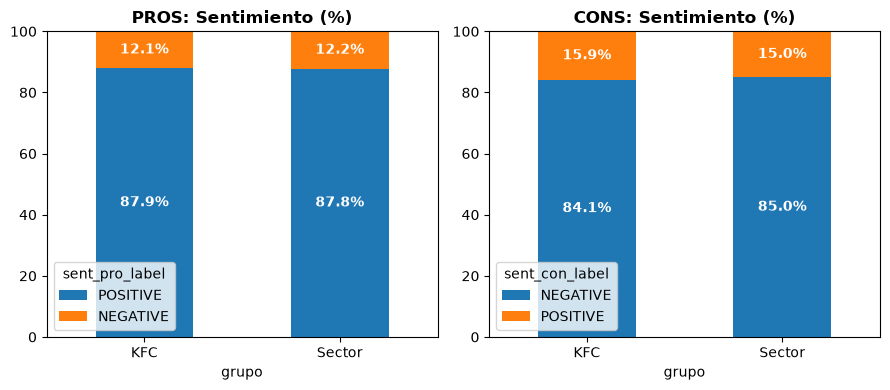

In [13]:
# ==============================================================================
# VISUALIZACIÓN DE SENTIMIENTO EN PROS Y CONS
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definir grupo: Empresa Target vs Sector
df['grupo'] = df['firm'].apply(lambda x: 'KFC' if x == 'KFC' else 'Sector')

# 2. Tablas cruzadas en porcentaje (%)
pros = pd.crosstab(df['grupo'], df['sent_pro_label'], normalize='index')[['POSITIVE', 'NEGATIVE']] * 100
cons = pd.crosstab(df['grupo'], df['sent_con_label'], normalize='index')[['NEGATIVE', 'POSITIVE']] * 100

# 3. Dibujar en 2 paneles limpios
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

# Panel PROS
pros.plot(kind='bar', stacked=True, ax=ax1, rot=0)
ax1.set_title('PROS: Sentimiento (%)', fontweight='bold')
ax1.set_ylim(0, 100)
for c in ax1.containers:
    ax1.bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

# Panel CONS
cons.plot(kind='bar', stacked=True, ax=ax2, rot=0)
ax2.set_title('CONS: Sentimiento (%)', fontweight='bold')
ax2.set_ylim(0, 100)
for c in ax2.containers:
    ax2.bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

El control de calidad con DistilBERT confirma la fiabilidad del dataset de Glassdoor: 
- los Pros registran un ~88% de polaridad positiva 
- los Cons un ~84-85% negativa,
- con un comportamiento prácticamente idéntico entre KFC y la competencia (Domino's, McDonald's, Starbucks y Subway). 

---
## 3. Topic Modeling con BERTopic
- Aplicar BERTOPIC (Ejecución del modelo)
- Asignación de Etiquetas de Negocio (Diccionarios)
- Revisión de Comentarios por Tema (Validación)

In [14]:
import pandas as pd
import numpy as np
import umap
from hdbscan import HDBSCAN
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction import text
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

# ================================================================
# TOPIC MODELING CON BERTOPIC
# ================================================================
# 1. Stop words estándar de NLTK
nltk_stopwords = set(stopwords.words('english'))

# 2. Stop words específicas de las reseñas de Glassdoor
glassdoor_stopwords = {
    'good', 'great', 'pros', 'cons', 'work', 'working', 'job',
    'store', 'think', 'ok', 'okay', 'place', 'say', 'dont',
    'doesnt', 'really', 'like', 'get', 'got', 'make', 'lots',
    'lot', 'na', 'idk'
}

# 3. Unir ambos conjuntos
custom_stopwords = sorted(nltk_stopwords.union(glassdoor_stopwords))

# 4. Vectorizador para BERTopic
vectorizer_model = CountVectorizer(
    stop_words=custom_stopwords,
    ngram_range=(1, 2),
    min_df=2
)

# UMAP y HDBSCAN 
umap_model = umap.UMAP(
    n_components=5, 
    n_neighbors=15, 
    min_dist=0.0, 
    metric="cosine", 
    random_state=42
)
hdbscan_model = HDBSCAN(
    min_cluster_size=25,# para evitar micro-clusters ruidosos
    min_samples=2,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

# FUNCIÓN DE ENTRENAMIENTO Y EJECUCIÓN (TARGET = 5 TOPICS)
def entrenar_bertopic_limpio(textos, target_topics=6):
    # 1. Instanciar BERTopic con los submódulos configurados
    topic_model = BERTopic(
        language="english",
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        calculate_probabilities=True,
        verbose=False
    )
    
    # 2. Fit & Transform inicial
    topics, probs = topic_model.fit_transform(textos)
    
    # 3. Reducción exacta a 5 temas de negocio
    topic_model.reduce_topics(textos, nr_topics=target_topics)
    topics_reducidos = topic_model.topics_
    
    # 4. Reasignación de outliers (topic -1) al tema más afín
    new_topics = topic_model.reduce_outliers(textos, topics_reducidos, strategy="c-tf-idf")
    topic_model.update_topics(textos, topics=new_topics, vectorizer_model=vectorizer_model)
    
    return topic_model, new_topics

# ------------------------------------------------------------------------------
# ENTRENAMIENTO UNIFICADO PARA PROS Y CONS (5 TEMAS)
# ------------------------------------------------------------------------------
# 1. Ejecución sobre PROS (todas las empresas juntas)
print("=== ENTRENANDO BERTOPIC SOBRE PROS (6 TEMAS) ===")
docs_pros = df['pros'].astype(str).tolist()
topic_model_pros, df['topic_pro_id'] = entrenar_bertopic_limpio(docs_pros, target_topics=6)

display("[PROS] Resumen de los 6 temas identificados:", 
        topic_model_pros.get_topic_info()[['Topic', 'Count', 'Name', 'Representation']].head(6))

# 2. Ejecución sobre CONS (todas las empresas juntas)
print("\n=== ENTRENANDO BERTOPIC SOBRE CONS (6 TEMAS) ===")
docs_cons = df['cons'].astype(str).tolist()
topic_model_cons, df['topic_con_id'] = entrenar_bertopic_limpio(docs_cons, target_topics=6)

display("[CONS] Resumen de los 6 temas identificados:", 
        topic_model_cons.get_topic_info()[['Topic', 'Count', 'Name', 'Representation']].head(6))



[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\rubye\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


=== ENTRENANDO BERTOPIC SOBRE PROS (6 TEMAS) ===


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-12 22:22:11,612 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


'[PROS] Resumen de los 6 temas identificados:'

...


=== ENTRENANDO BERTOPIC SOBRE CONS (6 TEMAS) ===


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-12 22:22:49,275 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


'[CONS] Resumen de los 6 temas identificados:'

,Topic,Count,Name,Representation
0,-1,8,-1_aint___,"[aint, , , , , , , , , ]"
1,0,8711,0_pay_hours_management_customers,"[pay, hours, management, customers, low, bad, ..."
2,1,433,1_none_nothing_everything_bad,"[none, nothing, everything, bad, nothing bad, ..."
3,2,377,2_company_con_many_downsides,"[company, con, many, downsides, downside, didn..."
4,3,228,3_car_wear_tear_wear tear,"[car, wear, tear, wear tear, vehicle, miles, g..."
5,4,137,4_feet_standing_day_long,"[feet, standing, day, long, time, hours, hours..."


In [15]:
# ------------------------------------------------------------------------------
# Asignación de Etiquetas 
# ------------------------------------------------------------------------------

# DICCIONARIO PARA PROS
label_map_pros = {
    -1: "Otros",
     0: "Beneficios y Flexibilidad",
     1: "Compañeros y Aprendizaje",
     2: "Producto y Descuentos",
     3: "Sin Ventajas Destacadas",
     4: "Valoración Positiva General"
}

# DICCIONARIO PARA CONS
label_map_cons = {
    -1: "Otros",
     0: "Salario, Horarios y Gestión",
     1: "Sin Quejas Destacadas",
     2: "Problemas con la Empresa",
     3: "Gastos del Vehículo (Delivery)",
     4: "Exigencia Física"
}

# Asignar etiquetas a los temas
df["topic_pro_label"] = (df["topic_pro_id"].map(label_map_pros).fillna("Sin etiqueta"))
df["topic_con_label"] = (df["topic_con_id"].map(label_map_cons).fillna("Sin etiqueta"))

# Calcular la distribución porcentual global (%)
dist_pros_pct = (
    df["topic_pro_label"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

dist_cons_pct = (
    df["topic_con_label"]
    .value_counts(normalize=True, dropna=False)#convierte las proporciones en porcentajes.
    .mul(100)#convierte las proporciones en porcentajes.
    .round(2)#redondea a dos decimales.
)

display("=== DISTRIBUCIÓN PORCENTUAL DE PROS (%) ===",
        dist_pros_pct.to_frame(name="% del total de pros"))

display("=== DISTRIBUCIÓN PORCENTUAL DE CONS (%) ===", 
        dist_cons_pct.to_frame(name="% del total de cons"))

'=== DISTRIBUCIÓN PORCENTUAL DE PROS (%) ==='

,% del total de pros
topic_pro_label,
Beneficios y Flexibilidad,91.42
Compañeros y Aprendizaje,3.27
Valoración Positiva General,1.80
Producto y Descuentos,1.75
Sin Ventajas Destacadas,1.50
Otros,0.26


'=== DISTRIBUCIÓN PORCENTUAL DE CONS (%) ==='

,% del total de cons
topic_con_label,
"Salario, Horarios y Gestión",88.04
Sin Quejas Destacadas,4.38
Problemas con la Empresa,3.81
Gastos del Vehículo (Delivery),2.30
Exigencia Física,1.38
Otros,0.08


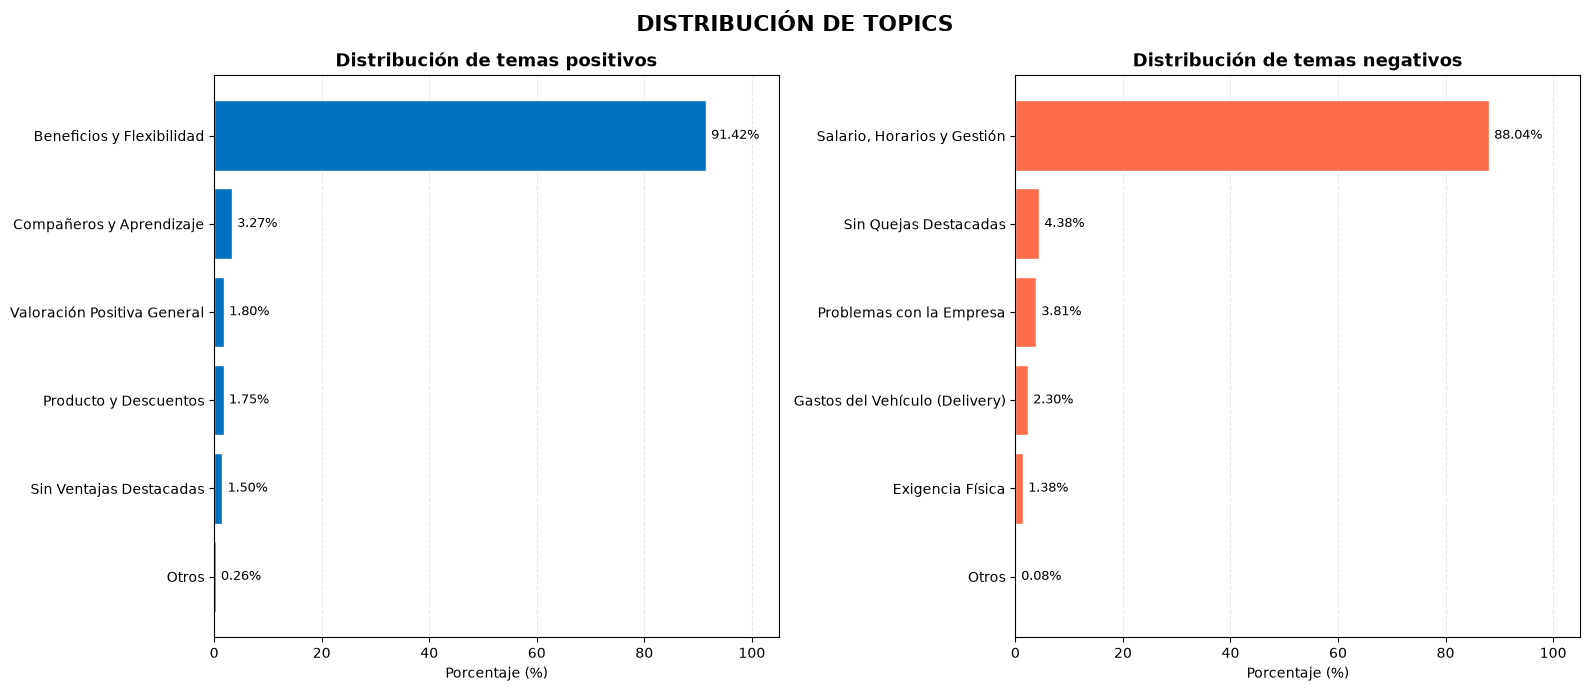

In [16]:

import matplotlib.pyplot as plt
import pandas as pd

# =====================================================
# VISUALIZACIÓN DE LA DISTRIBUCIÓN DE TOPICS: PROS/CONS
# =====================================================

# Colores
color_pros = "#0070C0"
color_cons = "#FF6E4A"

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# -------------------------
# 1. GRÁFICO DE PROS
# -------------------------
pros = dist_pros_pct.sort_values(ascending=True)

axes[0].barh(
    pros.index,
    pros.values,
    color=color_pros,
    edgecolor="white"
)

axes[0].set_title(
    "Distribución de temas positivos",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Porcentaje (%)")
axes[0].set_xlim(0, 105)
axes[0].grid(axis="x", linestyle="--", alpha=0.3)
axes[0].set_axisbelow(True)

for i, valor in enumerate(pros.values):
    axes[0].text(
        valor + 1, i,
        f"{valor:.2f}%",
        va="center",
        fontsize=9
    )

# -------------------------
# 2. GRÁFICO DE CONS
# -------------------------
cons = dist_cons_pct.sort_values(ascending=True)

axes[1].barh(
    cons.index,
    cons.values,
    color=color_cons,
    edgecolor="white"
)

axes[1].set_title(
    "Distribución de temas negativos",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Porcentaje (%)")
axes[1].set_xlim(0, 105)
axes[1].grid(axis="x", linestyle="--", alpha=0.3)
axes[1].set_axisbelow(True)

for i, valor in enumerate(cons.values):
    axes[1].text(
        valor + 1, i,
        f"{valor:.2f}%",
        va="center",
        fontsize=9
    )

fig.suptitle(
    "DISTRIBUCIÓN DE TOPICS",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [17]:
topic_model_pros.visualize_barchart()

In [18]:
topic_model_cons.visualize_barchart()

In [19]:
# === Revisión de Comentarios por Tema ===
# Para revisar los comentarios asociados a cada tema.
# Esto permite validar si los temas identificados por el modelo son coherentes con el contenido de los comentarios.
import pandas as pd
import pandas as pd

def revisar_todos_los_temas(
    df, columna_texto, modelo, label_map, n=10
):
    temas = modelo.topics_

    if len(df) != len(temas):
        print(
            f"Error: df tiene {len(df)} filas, "
            f"pero el modelo tiene {len(temas)} temas."
        )
        print("Utiliza el DataFrame con el que entrenaste el modelo.")
        return

    # Asociar cada tema con su comentario por posición
    datos = pd.DataFrame({
        "comentario": df[columna_texto].to_numpy(),
        "tema": temas
    })

    for topic_id in sorted(datos["tema"].unique()):
        comentarios = datos.loc[
            datos["tema"] == topic_id, "comentario"
        ].dropna()

        comentarios = comentarios[
            comentarios.astype(str).str.strip().ne("")
        ]

        print("\n" + "=" * 60)
        print(f"TEMA {topic_id}: {label_map.get(topic_id, 'Sin etiqueta')}")
        print(f"Total de comentarios: {len(comentarios)}")
        print("=" * 60)

        for i, comentario in enumerate(
            comentarios.sample(
                n=min(n, len(comentarios)),
                random_state=42
            ),
            start=1
        ):
            print(f"{i}. {comentario}\n")

print("\n=== REVISIÓN DE TEMAS EN PROS ===")
revisar_todos_los_temas(
    df=df,
    columna_texto="pros",
    modelo=topic_model_pros,
    label_map=label_map_pros,
    n=10
)
print("\n=== REVISIÓN DE TEMAS EN CONS ===")
revisar_todos_los_temas(
    df=df,
    columna_texto="cons",
    modelo=topic_model_cons,
    label_map=label_map_cons,
    n=10
)


=== REVISIÓN DE TEMAS EN PROS ===

TEMA -1: Otros
Total de comentarios: 26
1. Secured job for intra immigrants

2. Good store to work with

3. Not a great place to work

4. Not applicable for the job

5. Great good promising good partimer

6. Compañerismo que suele verse entre los más jovenes.

7. The great job it was.

8. I like to work overseas

9. Its just not all that

10. It was a 9 to 5 job


TEMA 0: Beneficios y Flexibilidad
Total de comentarios: 9045
1. Definitely good when you have good coworkers

2. Plenty of Hours Each Week

3. Management are good and plenty of overtime opportunities

4. -They take care of their employees -Fantastic benefits for a retail coffee shop -Great roll model company for others to follow: the free education through ASU, reduced healthcare, putting their partners first during the pandemic, free food and drink, stock shares, the list goes on....

5. Formation is very well structured. Partners (employees) encourage and help each other a lot.

6. Good c

**PROS (Aspectos Positivos)**
- Topic -1 (Otros) [26 comentarios]: Ruido, respuestas breves o inclasificables ("Secured job", "Good store to work with").
- Topic 0 (Beneficios y Flexibilidad) [9,045 comentarios]: Representa el gran bloque de atracción. Incluye comida gratis, horarios flexibles y facilidades para compaginar.
- Topic 1 (Compañeros y Aprendizaje) [324 comentarios]: Centrado en las relaciones interpersonales, hacer amigos ("meet new people", "make new friends") y adquirir habilidades ("lots of skills can be learned").
- Topic 2 (Producto y Descuentos) [173 comentarios]: Menciones sobre la comida (nuggets, patatas), el descuento de personal y el cuidado/trato a los empleados.
- Topic 3 (Ausencia de Ventajas / Sin Pros) [148 comentarios]: Reseñas explícitamente negativas en la casilla de pros ("none at all", "nothing", "there are no pros").
- Topic 4 (Valoración Positiva General) [178 comentarios]: Evaluaciones positivas genéricas ("love it so much", "all good", "decent job").


**CONS (Aspectos Negativos)**
- Topic -1 (Otros) [8 comentarios]: Comentarios residuales fuera de patrón.
- Topic 0 (Salario, Horarios y Gestión) [8,711 comentarios]: Concentra el volumen principal de quejas. Trata sobre sueldos bajos, exceso de horas, presión, clientes y gestión/managers.
- Topic 1 (Ausencia de Quejas / Sin Cons) [433 comentarios]: Empleados que declaran no tener ninguna queja ("nothing i really enjoyed my team", "none as of yet", "nothing bad").
- Topic 2 (Problemas con la Empresa) [377 comentarios]: Comentarios sobre las desventajas o inconvenientes generales de la compañía y la atención al cliente ("downsides of working here").
- Topic 3 (Gastos del Vehículo / Delivery) [228 comentarios]: Específico de reparto, centrado en el desgaste del coche (wear and tear), gasolina y kilometraje.

---
### 4. COMPARACIÓN CON PEERS Y BALANCE NETO
- Tabla Comparativa de Balance Neto (% PROS - % CONS) 
- Gráfico de Gap Competitivo (PROS y CONS por separado)
- Gráfico de Gap de Balance Neto

In [20]:
# ==============================================================================
# Tabla Comparativa de Balance Neto (% PROS - % CONS) 
# ==============================================================================
TARGET_FIRM = 'KFC'  # Nombre exacto de KFC en la columna 'firm'

# Porcentajes de PROS y CONS por empresa y categoría
pros_by_firm = pd.crosstab(df['firm'], df['topic_pro_label'], normalize='index') * 100
cons_by_firm = pd.crosstab(df['firm'], df['topic_con_label'], normalize='index') * 100

# Igualar columnas entre PROS y CONS
todas_las_categorias = list(set(pros_by_firm.columns).union(set(cons_by_firm.columns)))
pros_by_firm = pros_by_firm.reindex(columns=todas_las_categorias, fill_value=0)
cons_by_firm = cons_by_firm.reindex(columns=todas_las_categorias, fill_value=0)

# Calcular Balance Neto (% PROS - % CONS)
balance_neto = pros_by_firm - cons_by_firm

# Separar KFC y calcular la media de los Peers (Competencia)
balance_target = balance_neto.loc[TARGET_FIRM]
balance_peers_mean = balance_neto.drop(index=TARGET_FIRM).mean(axis=0)

# Calcular Gap de Balance (KFC - Media Peers)
gap_balance = balance_target - balance_peers_mean

# Crear la tabla df_comparativa
df_comparativa = pd.DataFrame({
    f'{TARGET_FIRM} (% PROS)': pros_by_firm.loc[TARGET_FIRM],
    f'{TARGET_FIRM} (% CONS)': cons_by_firm.loc[TARGET_FIRM],
    f'{TARGET_FIRM} Balance Neto': balance_target,
    'Peers Media Balance Neto': balance_peers_mean,
    'Gap de Balance (Diferencial)': gap_balance
}).round(2).sort_values(by='Gap de Balance (Diferencial)', ascending=False)

print("=== TABLA COMPARATIVA DE RRHH (KFC vs SECTOR) ===")
display(df_comparativa)

=== TABLA COMPARATIVA DE RRHH (KFC vs SECTOR) ===


,KFC (% PROS),KFC (% CONS),KFC Balance Neto,Peers Media Balance Neto,Gap de Balance (Diferencial)
Gastos del Vehículo (Delivery),0.00,0.79,-0.79,-2.67,1.88
Compañeros y Aprendizaje,4.57,0.00,4.57,2.97,1.61
Producto y Descuentos,2.73,0.00,2.73,1.51,1.22
Exigencia Física,0.00,0.84,-0.84,-1.51,0.67
Sin Ventajas Destacadas,1.89,0.00,1.89,1.40,0.49
Valoración Positiva General,2.05,0.00,2.05,1.74,0.31
Otros,0.42,0.11,0.32,0.15,0.17
"Salario, Horarios y Gestión",0.00,88.22,-88.22,-88.00,-0.22
Problemas con la Empresa,0.00,4.63,-4.63,-3.62,-1.01
Sin Quejas Destacadas,0.00,5.42,-5.42,-4.13,-1.29


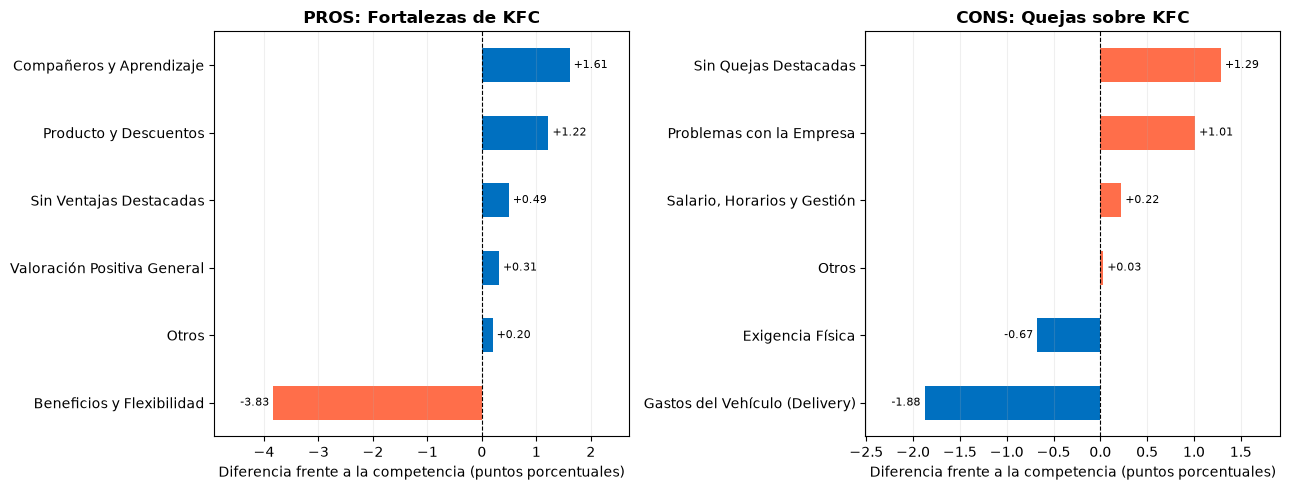

In [21]:
# ==============================================================================
# Gráfico de Gap Competitivo KFC (Pros/Cons por separado)
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

TARGET_FIRM = "KFC"

# 1. Distribución porcentual por empresa
pros = pd.crosstab(df["firm"], df["topic_pro_label"], normalize="index") * 100
cons = pd.crosstab(df["firm"], df["topic_con_label"], normalize="index") * 100

# 2. Diferencia entre KFC y la media de la competencia
gap_pros = (pros.loc[TARGET_FIRM] - pros.drop(TARGET_FIRM).mean()).sort_values()
gap_cons = (cons.loc[TARGET_FIRM] - cons.drop(TARGET_FIRM).mean()).sort_values()

# 3. Crear gráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))


for ax, datos, titulo, es_cons in [
    (ax1, gap_pros, "PROS: Fortalezas de KFC", False),
    (ax2, gap_cons, "CONS: Quejas sobre KFC", True)
]:
    colores = [
        "#0070C0" if (v <= 0 if es_cons else v >= 0) else "#FF6E4A"
        for v in datos
    ]

    datos.plot(kind="barh", ax=ax, color=colores)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Diferencia frente a la competencia (puntos porcentuales)")
    ax.set_ylabel("")
    ax.bar_label(ax.containers[0], fmt="%+.2f", padding=3, fontsize=8)
    ax.margins(x=0.2)
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


Desglose de Pros y Cons por Separado:
Permite auditar si los gaps competitivos se explican por el volumen de elogios o por la concentración de quejas.
* En PROS (Fortalezas): Confirma que la desventaja en *Beneficios y Flexibilidad (-3,83 pp)* no ocurre porque sea un tema negativo, sino porque los competidores (Starbucks/McDonald's) comunican con mayor éxito sus ventajas.
* En CONS (Quejas): Demuestra una paridad casi absoluta en *Salario, Horarios y Gestión (+0,22 pp)* entre KFC y sus competidores, confirmando que la insatisfacción con el sueldo de entrada y la rotación de turnos es un problema estructural de toda la industria QSR.

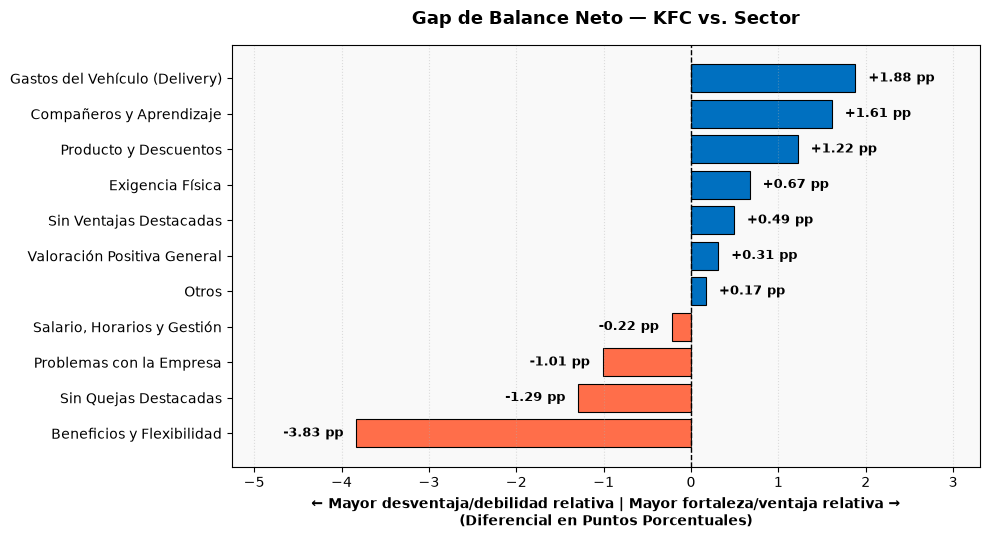

In [22]:
# ==============================================================================
# GRÁFICO DE GAP DE BALANCE NETO (KFC vs. SECTOR)
# ==============================================================================
import matplotlib.pyplot as plt

# 1. Preparar datos de la tabla df_comparativa (ordenados de menor a mayor)
datos_gap = df_comparativa['Gap de Balance (Diferencial)'].sort_values(ascending=True)

# 2. Colores: Verde si KFC tiene ventaja (Gap > 0), Rojo si es desventaja (Gap < 0)
colores = ['#0070C0' if v > 0 else '#FF6E4A' for v in datos_gap]

# 3. Crear figura
fig, ax = plt.subplots(figsize=(10, 5.5))

# Dibujar barras horizontales
bars = ax.barh(datos_gap.index, datos_gap.values, color=colores, edgecolor='black', linewidth=0.8)

# Línea de referencia en cero (Equilibrio con la competencia)
ax.axvline(0, color='black', linestyle='--', linewidth=1, label='Media de Peers (Gap = 0)')

# 4. Añadir etiquetas numéricas sobre cada barra
for bar in bars:
    val = bar.get_width()
    offset = 0.15 if val >= 0 else -0.15
    align = 'left' if val >= 0 else 'right'
    ax.text(
        val + offset, 
        bar.get_y() + bar.get_height() / 2, 
        f'{val:+.2f} pp', 
        va='center', 
        ha=align, 
        fontsize=9, 
        fontweight='bold'
    )

# 5. Ajustes estéticos
ax.set_title('Gap de Balance Neto — KFC vs. Sector', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('← Mayor desventaja/debilidad relativa | Mayor fortaleza/ventaja relativa →\n(Diferencial en Puntos Porcentuales)', fontsize=10, fontweight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.4)
ax.set_facecolor('#f9f9f9')
ax.margins(x=0.25)
plt.tight_layout()


**Gap de Balance Neto:**
Este gráfico sintetiza la posición competitiva global de KFC en una sola métrica (% PROS − % CONS vs. Sector).
* Fortalezas: KFC lidera frente a sus competidores en Compañeros y Aprendizaje (+1,61 pp) y Producto y Descuentos (+1,22 pp), posicionando el buen clima laboral como su principal activo de marca empleadora.
* Áreas de Vulnerabilidad: Presenta su mayor rezago relativo en Beneficios y Flexibilidad (-3,83 pp) y una ligera desventaja en Salario, Horarios y Gestión (-0,22 pp). 
* Aunque Beneficios y Flexibilidad es un aspecto positive valorado internamente, la competencia lo implementa major.


---
## 5. Empleados actuales vs. antiguos

- Tablas Cruzadas de Quejas por Estado
- Gráfico Comparativo de Motivos de Salida
- Conclusiones de Retención (Markdown)

In [23]:
# ==============================================================================
# EMPLEADOS ACTUALES VS. ANTIGUOS (MOTIVOS DE SALIDA EN KFC)
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
import pandas as pd

TARGET_FIRM = "KFC"

# 1. Filtrar los datos correspondientes a KFC
df_kfc = df[df["firm"] == TARGET_FIRM].copy()

# Identificar la columna de estado del empleado (tipo_empleado o status)
col_estado = (
    "tipo_empleado" if "tipo_empleado" in df_kfc.columns else "status"
)

# ------------------------------------------------------------------------------
# 1. TABLAS CRUZADAS DE QUEJAS POR ESTADO
# ------------------------------------------------------------------------------
# A) Frecuencias absolutas
tabla_quejas_abs = pd.crosstab(
    df_kfc[col_estado], df_kfc["topic_con_label"], margins=True
)

# B) Porcentajes por fila (normalizado por grupo de empleado)
tabla_quejas_pct = (
    pd.crosstab(
        df_kfc[col_estado], df_kfc["topic_con_label"], normalize="index"
    )
    * 100
)

print("=== TABLA 1: FRECUENCIA ABSOLUTA DE QUEJAS (Nº RESEÑAS) ===")
display(tabla_quejas_abs)

print("\n=== TABLA 2: DISTRIBUCIÓN PORCENTUAL DE QUEJAS POR ESTADO (%) ===")
display(tabla_quejas_pct.round(2))



=== TABLA 1: FRECUENCIA ABSOLUTA DE QUEJAS (Nº RESEÑAS) ===


topic_con_label,Exigencia Física,Gastos del Vehículo (Delivery),Otros,Problemas con la Empresa,"Salario, Horarios y Gestión",Sin Quejas Destacadas,All
tipo_empleado,,,,,,,
Actual,6,8,1,43,690,55,803
Antiguo,10,7,1,45,988,48,1099
All,16,15,2,88,1678,103,1902



=== TABLA 2: DISTRIBUCIÓN PORCENTUAL DE QUEJAS POR ESTADO (%) ===


topic_con_label,Exigencia Física,Gastos del Vehículo (Delivery),Otros,Problemas con la Empresa,"Salario, Horarios y Gestión",Sin Quejas Destacadas
tipo_empleado,,,,,,
Actual,0.75,1.00,0.12,5.35,85.93,6.85
Antiguo,0.91,0.64,0.09,4.09,89.90,4.37


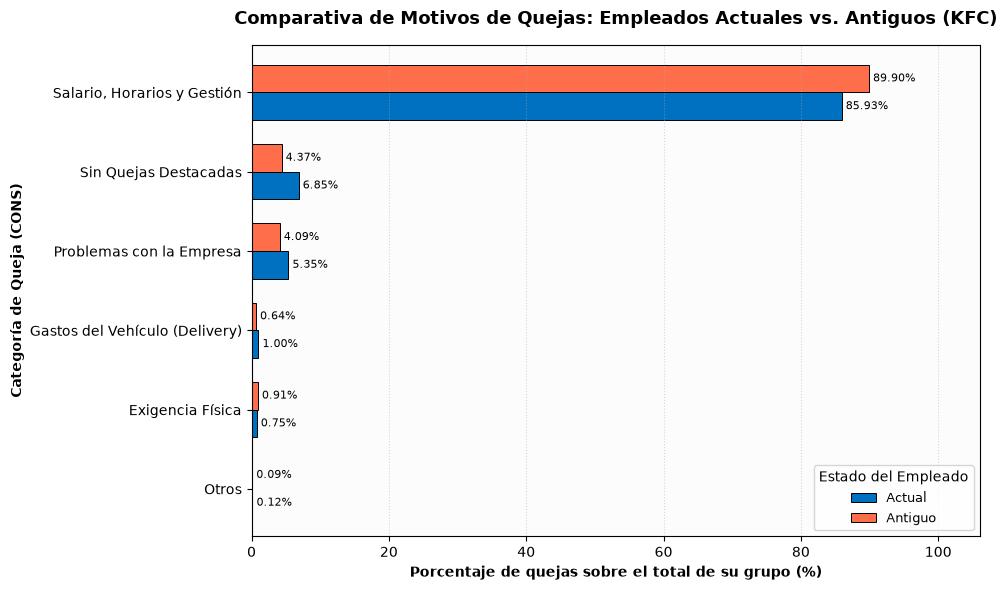

In [24]:
# ------------------------------------------------------------------------------
# 2. GRÁFICO COMPARATIVO DE MOTIVOS DE SALIDA
# ------------------------------------------------------------------------------

# Transponer la tabla de porcentajes para ordenar las barras
df_plot = tabla_quejas_pct.T.sort_values(
    by=tabla_quejas_pct.index[0], ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

# Paleta de colores: Azul para activos, Naranja/Rojo para ex-empleados
colores = ["#0070C0", "#FF6E4A"]

# Dibujar barras horizontales agrupadas
df_plot.plot(
    kind="barh", ax=ax, color=colores, edgecolor="black", linewidth=0.7, width=0.7
)

# Estilo visual y títulos
ax.set_title(
    f"Comparativa de Motivos de Quejas: Empleados Actuales vs. Antiguos ({TARGET_FIRM})",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel(
    "Porcentaje de quejas sobre el total de su grupo (%)",
    fontsize=10,
    fontweight="bold",
)
ax.set_ylabel("Categoría de Queja (CONS)", fontsize=10, fontweight="bold")
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.legend(
    title="Estado del Empleado",
    frameon=True,
    facecolor="white",
    fontsize=9,
    title_fontsize=10,
)
ax.set_facecolor("#fcfcfc")

# Añadir las etiquetas con el porcentaje exacto en cada barra
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=8)

ax.margins(x=0.18)
plt.tight_layout()
plt.show()

La nota media cae de **3.51** en empleados actuales a **3.18** en ex-empleados
  
**Salario, Horarios y Gestión** concentra el **85.93%** de las quejas en la plantilla activa y se eleva al **89.90%** en los trabajadores salientes.

### 6. MATRIZ DE PRIORIZACIÓN DE RRHH
- Gráfico Scatter de Matriz de Priorización (con adjustText)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


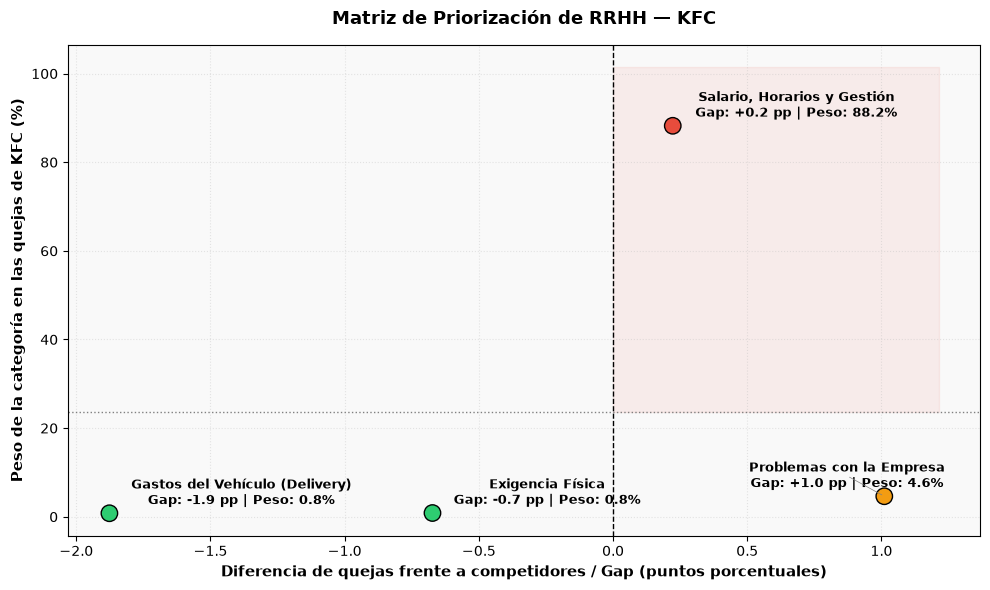

In [25]:
# ==============================================================================
# MATRIZ DE PRIORIZACIÓN DE RRHH (KFC vs. PEERS)
# Eje X: Diferencia de quejas frente a competidores (Gap en pp)
# Eje Y: Peso de la categoría en las quejas de KFC (%)
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt
from adjustText import adjust_text

TARGET_FIRM = "KFC"

# 1. Porcentaje de quejas por empresa y categoría
cons = pd.crosstab(df["firm"], df["topic_con_label"], normalize="index") * 100

# 2. Peso de cada categoría en KFC y diferencia (Gap) frente a la media de peers
peso_kfc = cons.loc[TARGET_FIRM]
gap = peso_kfc - cons.drop(index=TARGET_FIRM).mean()

# 3. Crear DataFrame de la matriz excluyendo categorías no accionables de ruido
matriz = pd.DataFrame({
    "Peso": peso_kfc,
    "Gap": gap
}).drop(index=["Otros", "Otros / Ruido", "Sin Quejas Destacadas"], errors="ignore")

# 4. Umbral de volumen (peso medio de las categorías)
umbral = matriz["Peso"].mean()

# 5. Asignación de colores por cuadrante de prioridad
colores = [
    "#e74c3c" if p >= umbral and g > 0 else  # Rojo: Prioridad Alta (Alto volumen + Peor que peers)
    "#f39c12" if g > 0 else                 # Naranja: Alerta Secundaria (Bajo volumen + Peor que peers)
    "#2ecc71"                               # Verde: Fortaleza Operativa (Mejor o igual que peers)
    for p, g in zip(matriz["Peso"], matriz["Gap"])
]

# 6. Generar el gráfico de dispersión (Scatter Plot)
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    matriz["Gap"], matriz["Peso"],
    c=colores, s=140, edgecolor="black", zorder=3
)

# Líneas de referencia
ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Equilibrio Sector (Gap = 0)")
ax.axhline(umbral, color="gray", linestyle=":", linewidth=1, label=f"Umbral Medio ({umbral:.1f}%)")

# Sombreado del cuadrante de Prioridad Alta (Zona Roja)
max_gap = max(matriz["Gap"].max() * 1.2, 0.5)
max_peso = matriz["Peso"].max() * 1.15
ax.fill_between([0, max_gap], umbral, max_peso, color="#e74c3c", alpha=0.08)

# Añadir etiquetas con adjustText para evitar solapamientos
texts = []
for categoria, fila in matriz.iterrows():
    texts.append(
        ax.text(
            fila["Gap"], fila["Peso"],
            f"{categoria}\nGap: {fila['Gap']:+.1f} pp | Peso: {fila['Peso']:.1f}%",
            fontsize=9, fontweight="bold"
        )
    )

adjust_text(
    texts,
    ax=ax,
    expand_points=(1.2, 1.4),
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
)

# Configuración estética
ax.set_title("Matriz de Priorización de RRHH — KFC", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Diferencia de quejas frente a competidores / Gap (puntos porcentuales)", fontsize=11, fontweight="bold")
ax.set_ylabel("Peso de la categoría en las quejas de KFC (%)", fontsize=11, fontweight="bold")
ax.grid(alpha=0.3, linestyle=":")
ax.set_facecolor("#f9f9f9")

plt.tight_layout()



* Salario, Horarios y Gestión representa el 88.2% del volumen total de insatisfacción y supera la media del sector en quejas (+0.2 pp).
* Problemas con la Empresa (4.6% del volumen) aunque el volumen es bajo, es la categoría con el gap desfavorable más abultado en quejas
- Fortalezas Operativas: El reparto y la carga física presentan menor incidencia negativa que en la competencia, actuando como elementos de estabilidad operativa.

### Analizar  si es posible separar el topic  "Salario, Horarios y Gestión" para entender cual es el que mas afecta.

In [26]:
# ==============================================================================
# Sub-clustering con BERTopic para analizar subtemas dentro del gran cluster de quejas (Topic 0 de CONS)
# ==============================================================================

# 1. Filtrar los comentarios del gran cluster de quejas (Topic 0 de CONS)
df_gestion = df[df['topic_con_label'] == "Salario, Horarios y Gestión"].copy()

# 2. Entrenar un BERTopic específico para este subconjunto (forzando 3 subtemas)
topic_model_sub, df_gestion['subtopic_id'] = entrenar_bertopic_limpio(
    df_gestion['cons_clean'].tolist(), 
    target_topics=4
)

# 3. Ver qué palabras clave caracterizan a cada uno de los 3 subgrupos
display(topic_model_sub.get_topic_info())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-12 22:23:24,004 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,1,-1____,"[, , , , , , , , , ]",[management cut my hours every time i made a m...
1,0,7530,0_pay_hours_management_customers,"[pay, hours, management, customers, low, bad, ...","[dull job - very low pay, customers can be rud..."
2,1,814,1_food_starbucks_fast food_people,"[food, starbucks, fast food, people, fast, com...","[junk food a lot of junk management, some cust..."
3,2,366,2_smell_cleaning_hot_greasy,"[smell, cleaning, hot, greasy, dirty, clean, s...","[you smell like greasy food all the time, you ..."


In [27]:
topic_model_sub.visualize_barchart()

=== DESGLOSE INTERNO DE LA PRINCIPAL QUEJA EN KFC (%) ===


subtopic_label
Salario, Horarios y Liderazgo    86.44
Olor a Grasa y Limpieza           9.34
Exigencia Física y Estrés         4.20
Otros / Ruido                     0.01
Name: proportion, dtype: float64

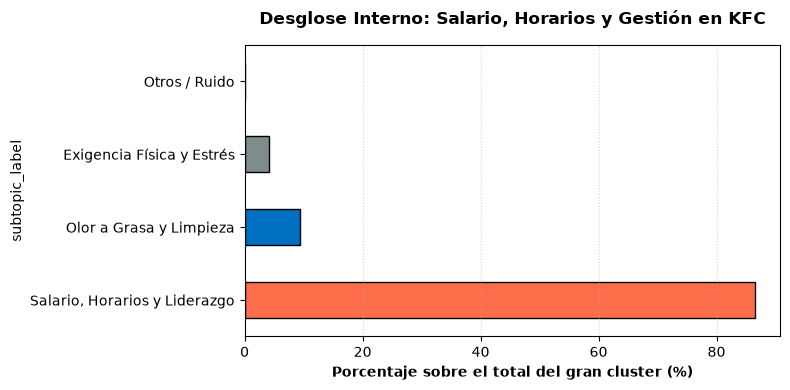

In [28]:
# ==============================================================================
# SUB-ANALYSIS: DESGLOSE DE LA CATEGORÍA CRÍTICA (SALARIO, HORARIOS Y GESTIÓN)
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

sublabel_map = {
    -1: "Otros / Ruido",
     0: "Salario, Horarios y Liderazgo",
     1: "Olor a Grasa y Limpieza",
     2: "Exigencia Física y Estrés",
}

df_gestion['subtopic_label'] = df_gestion['subtopic_id'].map(sublabel_map)

# 2. Distribución en porcentaje
dist_subquejas = (df_gestion['subtopic_label'].value_counts(normalize=True) * 100).round(2)
print("=== DESGLOSE INTERNO DE LA PRINCIPAL QUEJA EN KFC (%) ===")
display(dist_subquejas)

# 3. Gráfico de tarta / barras del desglose
fig, ax = plt.subplots(figsize=(8, 4))


dist_subquejas.plot(kind='barh', ax=ax, color=['#FF6E4A', '#0070C0', '#7f8c8d'], edgecolor='black')

ax.set_title('Desglose Interno: Salario, Horarios y Gestión en KFC', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Porcentaje sobre el total del gran cluster (%)', fontsize=10, fontweight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()

---
## 7. Conclusiones y recomendaciones para RRHH

* **Puntos Fuertes (Ventajas Competitivas):**
  * **Buen clima laboral:** El ambiente entre compañeros y el aprendizaje en tienda destacan por encima de la competencia (**+1,61 pp**).
  * **Beneficios en producto:** La comida de personal y los descuentos corporativos son muy valorados (**+1,22 pp** vs. peers).
* **Áreas de Mejora (Riesgos Internos):**
  * **Salario, Horarios y Gestión:** Representa el **88,2% del total de quejas** en KFC y es el motivo de casi **9 de cada 10 salidas de empleados**.
  * **Flexibilidad de turnos:** Aunque es un punto apreciado internamente, la competencia ofrece mejor percepción de horarios (**-3,83 pp** por debajo del sector).
  * **Previsibilidad de Horarios:** Implementar cuadrantes de turnos rotativos con semanas de antelación para reducir la fatiga operativa.